# NHL: предсказать успешность команды в следующем сезоне

**Тестовое задание • 100 баллов**

Вы аналитик, которому после окончания сезона нужно оценить перспективы команды
на следующий год. Соберите таблицу с учебного сайта
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/),
изучите данные и постройте модель классификации.
В работе оцениваются корректность исследования и обоснованность решений.

Ориентир времени: 6-10 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами и исходный `data/hockey_raw.csv` разместите на платформе githib.com.
Укажите имя, дату и использованные источники и инструменты в README.

## Что предсказывает модель

Одна строка признаков описывает команду в сезоне `t`.
`target=1`, если доля побед той же команды в сезоне `t+1` строго выше медианной
доли побед всех команд в сезоне `t+1`. В остальных случаях `target=0`.

Медиану считайте по полной исходной таблице будущего года до отбора пар.
В пары включайте одинаковые названия команды с разницей меток сезонов ровно в один год.
Строки без пары исключайте и учитывайте в описании данных.
Будущий `win_rate` и будущая медиана используются для построения target и анализа
готовых прогнозов. Признаки модели должны быть известны после сезона `t`.

## Схема проверки

Делите данные по году целевого сезона:

| Часть | target_year | Назначение |
|---|---|---|
| train | не позднее 2005 | Подготовка данных и обучение |
| validation | 2006-2008 | Сравнение вариантов и выбор решения |
| test | 2009-2011 | Одна итоговая оценка выбранного решения |

Основная метрика: ROC-AUC по вероятности класса 1.
На итоговом этапе также используйте F1 и accuracy при пороге 0.5.
Финальный test используйте после выбора решения на validation.

## Как оценивается работа

| Область | Баллы |
|---|---:|
| Сбор и понимание данных | 15 |
| Построение задачи и корректность проверки | 20 |
| Исследовательский анализ | 20 |
| Модели и эксперименты | 25 |
| Итоговая оценка и анализ ошибок | 15 |
| Ясность и воспроизводимость | 5 |
| **Всего** | **100** |

Ниже перечислены обязательные этапы работы. Внутри них вы самостоятельно выбираете
исследовательские вопросы, графики, признаки, обработку данных, эксперимент и способ
разбора ошибок. Оценивается качество решений, а не совпадение с эталонным маршрутом.
Сложность метода сама по себе не даёт преимущества. Корректный эксперимент может
получить полный балл и в случае отсутствия улучшения.

## Требования к сбору

Итоговая исходная таблица должна иметь столбцы `team`, `year`, `wins`, `losses`,
`ot_losses`, `win_rate`, `goals_for`, `goals_against`, `goal_diff`.
Самостоятельно исследуйте страницу и определите способ получения всей таблицы.

**Автор:** Волков Егор

**Дата:** 08.10.26

**Использованные источники и инструменты:** Antigravity IDE (Gemini 3.8 Flash)

In [1]:
# Ваши импорты и настройки
import os
import pandas as pd
import requests
import numpy as np
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score


## Раздел 1. Сбор и понимание данных: 15 баллов

### 1.1. Соберите и сохраните данные

Соберите все страницы сайта в одну таблицу с указанными девятью столбцами.
Сохраните исходную выгрузку в `data/hockey_raw.csv`. Укажите URL и дату сбора,
число обработанных страниц и число строк. Покажите, как проверили,
что сбор не ограничился первой страницей и при повторном анализе можно читать CSV.

In [2]:
# 1.1. Ваш код
# Добавьте ячейки при необходимости.
data = []
page = 1

while True:
    url = f"https://www.scrapethissite.com/pages/forms/?page_num={page}&per_page=100"
    print(f"Обработка страницы {page}")
    r = requests.get(url)
    df_page = pd.read_html(r.text)[0]
    if df_page.empty:
        print(f"Страница {page} пустая, дальше данных нет")
        break
    data.append(df_page)
    page += 1

df = pd.concat(data, ignore_index=True)
df.columns = ['team', 'year', 'wins', 'losses', 'ot_losses', 'win_rate', 'goals_for', 'goals_against', 'goal_diff']

os.makedirs('data', exist_ok=True)
df.to_csv('data/hockey_raw.csv', index=False)

print(df.shape)
df.head()

Обработка страницы 1
Обработка страницы 2
Обработка страницы 3
Обработка страницы 4
Обработка страницы 5
Обработка страницы 6
Обработка страницы 7
Страница 7 пустая, дальше данных нет
(582, 9)


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25


In [3]:
# Проверка данных в сохраненной таблице
df = pd.read_csv('data/hockey_raw.csv')
print(df.shape)
df.head()

(582, 9)


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25


**Ответ 1.1:**

Спарсили данные со страниц https://www.scrapethissite.com/pages/forms/?page_num={page}&per_page=100, где page - номер страницы. На момент 02.10.26 данные располагались на 6 страницах, если брать ограничение до 100 элементов на страницу. Всего получилось 582 строки.

Далее мы удостоверились, что данные сохранились в файл `data/hockey_raw.csv`. При выводе размера датафрейма и первых строк видно, что сохраненные в файл данные соответствуют собранным данным.

### 1.2. Проверьте качество таблицы

Изучите типы, пропуски и уникальность пары команда-год.
Добавьте не менее двух проверок согласованности, которые считаете важными
для последующего анализа. Покажите найденные особенности и обоснуйте
решения по их обработке. Сами проверки и способ представления результата выберите самостоятельно.

In [4]:
# 1.2. Ваш код
# Добавьте ячейки при необходимости.
print("\tтипы данных:")
print(df.dtypes)
print("\tчисло пропусков по столбцам")
print(df.isna().sum())

	типы данных:
team              object
year               int64
wins               int64
losses             int64
ot_losses        float64
win_rate         float64
goals_for          int64
goals_against      int64
goal_diff          int64
dtype: object
	число пропусков по столбцам
team               0
year               0
wins               0
losses             0
ot_losses        224
win_rate           0
goals_for          0
goals_against      0
goal_diff          0
dtype: int64


In [5]:
# считаем, в каких годах сколько раз значений 
df.groupby('year')['ot_losses'].count()


year
1990     0
1991     0
1992     0
1993     0
1994     0
1995     0
1996     0
1997     0
1998     0
1999    28
2000    30
2001    30
2002    30
2003    30
2005    30
2006    30
2007    30
2008    30
2009    30
2010    30
2011    30
Name: ot_losses, dtype: int64

In [6]:
# считаем, сколько команд было в каждом году, чтобы узнать,
# совпадает ли число команд с 1999 года с числом строк, где не пропущен ot_losses
df.groupby('year')['ot_losses'].size()


year
1990    21
1991    22
1992    24
1993    26
1994    26
1995    26
1996    26
1997    26
1998    27
1999    28
2000    30
2001    30
2002    30
2003    30
2005    30
2006    30
2007    30
2008    30
2009    30
2010    30
2011    30
Name: ot_losses, dtype: int64

In [7]:
# Уникальность пары команда-год
print("Дубликаты команда-год:", df.duplicated(subset=['team', 'year']).sum())

# Проверка 1: разница шайб
print("Разница шайб совпадает:", (df['goal_diff'] == df['goals_for'] - df['goals_against']).all())

# Проверка 2: баланс забитых и пропущенных шайб по годам
print("Баланс шайб лиги по годам:", (df.groupby('year')['goals_for'].sum() == df.groupby('year')['goals_against'].sum()).all())


Дубликаты команда-год: 0
Разница шайб совпадает: True
Баланс шайб лиги по годам: True


In [8]:
# Считаем число матчей в году
games = (df['wins'] / df['win_rate']).round()
print("Варианты числа матчей в году:", sorted(games.unique()))


Варианты числа матчей в году: [48.0, 80.0, 82.0, 84.0]


In [9]:
# Смотрим годы с 48 матчами
print("Годы с 48 матчами:", df[games == 48]['year'].unique())

Годы с 48 матчами: [1994]


In [10]:
# считаем разницу между общим числом матчей и суммой побед и поражений,
# чтобы выяснить, есть ли неучтенные результаты матчей
diff = games - (df['wins'] + df['losses'] + df['ot_losses'].fillna(0))
diff

0      12.0
1      19.0
2       8.0
3       8.0
4       8.0
       ... 
577     0.0
578     0.0
579     0.0
580     0.0
581     0.0
Length: 582, dtype: float64

In [11]:
print("Годы, где сумма полностью сошлась (diff == 0):", sorted(df[diff == 0]['year'].unique()))
print("Годы, где есть неучтённые матчи (diff > 0):", sorted(df[diff > 0]['year'].unique()))


Годы, где сумма полностью сошлась (diff == 0): [2005, 2006, 2007, 2008, 2009, 2010, 2011]
Годы, где есть неучтённые матчи (diff > 0): [1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003]


In [12]:
# Сравнение среднего числа поражений до 1999 года и после
# исключаем 1994 год из-за аномального числа игр
full_seasons = df[df['year'] != 1994]

before_1999 = full_seasons[full_seasons['year'] < 1999]
after_1999 = full_seasons[full_seasons['year'] >= 1999]

print("До 1999: среднее число losses:", round(before_1999['losses'].mean(), 2))
print("После 1999: среднее число losses:", round(after_1999['losses'].mean(), 2))
print("После 1999: среднее число ot_losses:", round(after_1999['ot_losses'].mean(), 2))
print("После 1999: сумма всех поражений (losses + ot_losses):", 
      round((after_1999['losses'] + after_1999['ot_losses']).mean(), 2))


До 1999: среднее число losses: 35.6
После 1999: среднее число losses: 31.38
После 1999: среднее число ot_losses: 7.46
После 1999: сумма всех поражений (losses + ot_losses): 38.84


**Ответ 1.2:**

Мы вывели информацию о типах данных в столбцах, увидели, что пропуски есть только в столбце `ot_losses`, и проверили, что в датасете нет повторений названий команд для одного и того же года.

Показатель `ot_losses` отвечает за число проигрышей в овертаймах, который не считался до 1999 года, а после был указан у каждой команды. Поэтому пропуски `ot_losses` до 1999 года мы в дальнейшем заполним нулями (если этот столбец вообще понадобится), потому что до этого года, видимо, поражения в овертаймах шли в `losses`, так как среднее число `losses` после появления `ot_losses` снизилось.

Далее мы проверили данные в таблице на корректность: разность забитых шайб и пропущенных соответствует записям в столбце `goal_diff` для всех строк. Число забитых шайб за каждый год равно числу пропущенных шайб за этот год.

Потом было посчитано число матчей для каждого года. В 1994 году было всего 48 матчей, а в другие годы (кроме 2004, который не предоставлен в таблице) число матчей было примерно одинаково и варьировалось от 80 до 84. Так как в годах было разное количество матчей, для обучения модели может быть надежнее будет опираться на относительные показатели, например, на `win_rate`, а не на `wins`, либо же просто исключить 1994 год и обучаться на оставшихся данных, ведь в других годах число матчей отличается незначительно.

Далее мы посмотрели, есть ли у нас неучтенные матчи у каждой команды в каждом году. Получилось, что с 2005 года неучтенных матчей не оказалось. А до этого года, видимо, были ничьи, информации о которых в датасете изначально нет. Это объясняет, почему с 1999 года выросло общее число поражений по сравнению с промежутком до 1999 года, ведь до 1999 года во всех годах были ничьи.

## Раздел 2. Построение задачи и корректность проверки: 20 баллов

### 2.1. Постройте target

Соедините строку команды в сезоне `t` с той же командой ровно в сезоне `t+1`
и постройте target по определению задания. Покажите число полученных пар,
число и годы исключённых строк, а также число случаев равенства будущей медиане.
Проверьте расчёт вручную минимум на двух содержательно разных примерах.

In [13]:
# 2.1. Ваш код
# Добавьте ячейки при необходимости.
# Считаем медианы винрейта по полной таблице для каждого сезона
medians = df.groupby('year')['win_rate'].median()

# Формируем пары: сезон t соединяем со следующим сезоном t+1 для той же команды
df_next = df[['team', 'year', 'win_rate']].copy()
df_next.columns = ['team', 'target_year', 'win_rate_next']

pairs = df.copy()
pairs['target_year'] = pairs['year'] + 1
pairs = pd.merge(pairs, df_next, on=['team', 'target_year'], how='inner')

# Добавляем медиану целевого года
pairs['target_median'] = pairs['target_year'].map(medians)

# Строим target: 1, если будущий винрейт строго выше медианы, иначе 0
pairs['target'] = (pairs['win_rate_next'] > pairs['target_median']).astype(int)

# Основные показатели
print("Число исходных строк:", len(df))
print("Число полученных пар:", len(pairs))
print("Число исключенных строк:", len(df) - len(pairs))

# В каких годах сезона t строки остались без пары
excluded = df[~df.set_index(['team', df['year'] + 1]).index.isin(pairs.set_index(['team', 'target_year']).index)]
print("\nИсключенные строки по годам сезона t:")
excluded['year'].value_counts().sort_index()


Число исходных строк: 582
Число полученных пар: 516
Число исключенных строк: 66

Исключенные строки по годам сезона t:


1992     1
1994     1
1995     1
1996     1
2003    30
2005     1
2010     1
2011    30
Name: year, dtype: int64

In [14]:
# Случаи равенства медиане
equal_median = (pairs['win_rate_next'] == pairs['target_median']).sum()
print("\nЧисло случаев равенства будущей медиане:", equal_median)

# Баланс классов
print("\nРаспределение target:")
print(pairs['target'].value_counts())



Число случаев равенства будущей медиане: 23

Распределение target:
0    266
1    250
Name: target, dtype: int64


In [15]:
# Пример 1: команда, у которой винрейт в следующем сезоне выше медианы
ex1 = pairs[pairs['win_rate_next'] > pairs['target_median']].iloc[0]
print("Строка из таблицы pairs:")
print(ex1[['team', 'year', 'target_year', 'win_rate_next', 'target_median', 'target']])

print("\nСтрока из исходной таблицы на следующий сезон:")
print(df[(df['team'] == ex1['team']) & (df['year'] == ex1['target_year'])][['team', 'year', 'wins', 'losses', 'win_rate']])

# Пример 2: пограничный случай, где винрейт равен медиане
ex2 = pairs[pairs['win_rate_next'] == pairs['target_median']].iloc[0]
print("\nСтрока из таблицы pairs:")
print(ex2[['team', 'year', 'target_year', 'win_rate_next', 'target_median', 'target']])

print("\nСтрока из исходной таблицы на следующий сезон:")
print(df[(df['team'] == ex2['team']) & (df['year'] == ex2['target_year'])][['team', 'year', 'wins', 'losses', 'win_rate']])

Строка из таблицы pairs:
team             Boston Bruins
year                      1990
target_year               1991
win_rate_next             0.45
target_median            0.444
target                       1
Name: 0, dtype: object

Строка из исходной таблицы на следующий сезон:
             team  year  wins  losses  win_rate
21  Boston Bruins  1991    36      32      0.45

Строка из таблицы pairs:
team             New Jersey Devils
year                          1991
target_year                   1992
win_rate_next                0.476
target_median                0.476
target                           0
Name: 31, dtype: object

Строка из исходной таблицы на следующий сезон:
                 team  year  wins  losses  win_rate
53  New Jersey Devils  1992    40      37     0.476


Проверка правильности определения значения target:
1. Boston Bruins с 1990 на 1991 год:

В 1991 их винрейт был 0.45.

Медиана в 1991 году равна 0.444.

0.45 > 0.444, значит, target должен быть 1.

В pairs target = 1, верно.
<br>

2. New Jersey Devils с 1991 на 1992 год:

В 1992 году винрейт был 0.476.

Медиана в 1992 году равна 0.476.

0.476 = 0.476, значит, target должен быть 0.

В pairs target = 0, верно.

**Ответ 2.1:**

Мы посчитали медианный винрейт по каждому сезону и сформировали пары команд для года t и года t + 1, если в году t + 1 эта команда играла. Всего получилось 516 валидных пар и 66 строк было исключено. Все команды из 2003 и 2011 годов были исключены из формирования пар, потому что 2004 и 2012 годов в датасете нет. А также в некоторых годах (1992, 1994, 1995, 1996, 2005, 2010) по одной команде не нашлось пары, потому что в следующем году они не играли, либо играли под другим названием.

Мы установили target = 0 для тех команд, у которых винрейт <= медиане, а target = 1, у кого больше медианы. Винрейт оказывался равным медиане в 23 случаях. Число нулей и единиц получилось примерно равным (266 и 250 соответственно).

Посчитали для двух команд винрейт и сравнили его с медианным. По итогам сравнения значения target получились такими же, как и в парах.

### 2.2. Подготовьте временную проверку

Разделите пары на train, validation и test по заданным границам target_year.
Покажите для каждой части фактические годы, размер и долю класса 1.
Назовите минимум два столбца, которые появились при построении target,
но недоступны модели в момент прогноза. Объясните, почему случайное перемешивание
строк отвечало бы на другой вопрос, чем выбранная временная схема.

In [16]:
# 2.2. Ваш код
# Добавьте ячейки при необходимости.

# Разделение по границам target_year
train = pairs[pairs['target_year'] <= 2005]
val = pairs[(pairs['target_year'] >= 2006) & (pairs['target_year'] <= 2008)]
test = pairs[(pairs['target_year'] >= 2009) & (pairs['target_year'] <= 2011)]

# Выводим фактические годы, размер и долю класса 1
for name, part in [('train', train), ('validation', val), ('test', test)]:
    print(f"--- {name.upper()} ---")
    print("Фактические target_year:", sorted(part['target_year'].unique()))
    print("Фактические сезоны t:", sorted(part['year'].unique()))
    print("Число строк:", len(part))
    print("Доля класса 1:", round(part['target'].mean(), 4))
    print()


--- TRAIN ---
Фактические target_year: [1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003]
Фактические сезоны t: [1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002]
Число строк: 338
Доля класса 1: 0.4911

--- VALIDATION ---
Фактические target_year: [2006, 2007, 2008]
Фактические сезоны t: [2005, 2006, 2007]
Число строк: 89
Доля класса 1: 0.4719

--- TEST ---
Фактические target_year: [2009, 2010, 2011]
Фактические сезоны t: [2008, 2009, 2010]
Число строк: 89
Доля класса 1: 0.4719



**Ответ 2.2:**

Хоть мы в train брали годы до 2005 включительно, фактически мы имеем в target годы с 1991 по 2003, так как не было ни одной пары 2004-2005, потому что данных за 2004 год нет в нашем датасете. Всего сюда попало 338 пар, доля класса 1 составила 0.4911.

На валидации у нас для target попали годы с 2006 по 2008, получилось 89 пар с долей класса 1 - 0.4719.

На test у нас на target годы с 2009 по 2011, 89 пар с долей класса 1 - 0.4719.

При построении target у нас появились столбцы `win_rate_next` и `target_median`, которые недоступны модели на момент прогноза, потому что они содержат информацию о следующем году, то есть о будущем, которое мы хотим предсказать. Их использование привело бы к утечке данных.

Наша временная схема отвечает на вопрос "Будет ли команда успешной в следующем году, если знать ее успех в прошлые годы?", а если перемешать строки, то модель отвечала бы на вопрос "Как заполнить пропуски в данных на основе имеющихся?"

## Раздел 3. Исследовательский анализ: 20 баллов

### 3.1. Сформулируйте вопросы к данным

До построения основных графиков сформулируйте не менее двух собственных
исследовательских вопросов, связанных с будущей успешностью команд
или устройством данных. Для каждого запишите ожидаемый результат и объясните,
как ответ может повлиять на выбор признаков, обработку или интерпретацию модели.

**Ответ 3.1:**
1. Валидно ли обучать модель на одной парадигме, когда были ничьи, а тестировать на другой, где ничьих больше нет? С 2005 года, судя по датасету, ничьи перестали существовать. А у нас как раз train-выборка заканчивается на 2005 году, а далее идут валидационная и тестовая. Имеется ли смысл обучать модель на устаревших правилах?

Предположение: смысл имеется, но при обучении модели в первую очередь нужно обращать внимание на признаки, определение которых не менялось на всём датасете.

Возможно, вместо `win_rate` (который до отмены ничьих считался как частное побед на сумму побед, ничьих и поражений, а после отмены ничьих в знаменателе были только победы и поражения, и, соответственно, число побед выросло) для обучения модели лучше подойдет признак `goal_diff`, который считался одинаково для всех годов. Также будет полезно ввести отношение забитых голов к пропущенным `goals_for` / `goals_against`, чтобы корректно работать с 1994 годом, когда матчей было почти в 2 раза меньше, чем в остальные годы, и разность забитых и пропущенных голов по модулю может быть меньше, чем в остальные годы.

2. Насколько вероятно, что команда, успешная в текущем году, останется успешной в следующем? Быть может, успешной команде в текущем году просто повезло, и ее результаты упадут в следующем году, то есть произойдет регрессия к среднему.

Предположение: думаю, все-таки есть положительная корреляция между успехом команд в текущем и в следующем годах, потому что большая часть игроков (предположительно сильнее среднего), которые привели команду к успеху в текущем году, останется в этой команде и в следующем. Но нужно учитывать, что неуспешные команды сделают вывод из неудачного года, возможно, проведут замены или будут тренироваться усерднее успешных команд, из-за чего их конкурентоспособность вырастет и ранее успешным командам придется тяжелее сохранять лидерство.

Это говорит о том, что наша модель не может быть идеально точной, потому что существует слишком много неопределенности, которая никак не отражена в датасете через другие менее очевидные признаки.



### 3.2. Проведите исследовательский анализ

Ответьте на вопросы из пункта 3.1 с помощью числовых сводок и визуализаций.
Количество и типы графиков выберите сами: их должно быть достаточно,
чтобы подтвердить выводы, а каждый график должен отвечать на сформулированный вопрос.
Покажите хотя бы одно конкретное наблюдение на уровне команды или сезона.
Для каждого вывода укажите ограничение интерпретации.

In [17]:
# 3.2. Ваш код
# Добавьте ячейки при необходимости.

# Вопрос 1
# Добавляем отношение забитых шайб к пропущенным
pairs['goal_ratio'] = pairs['goals_for'] / pairs['goals_against']

# Выборка без тестовых данных
eda_pairs = pairs[pairs['target_year'] <= 2008].copy()

train_era = eda_pairs[eda_pairs['target_year'] <= 2005]
val_era = eda_pairs[(eda_pairs['target_year'] >= 2006) & (eda_pairs['target_year'] <= 2008)]

features = ['goal_diff', 'goal_ratio', 'win_rate']
corr_train = [train_era[f].corr(train_era['target']) for f in features]
corr_val = [val_era[f].corr(val_era['target']) for f in features]

# Числовая сводка корреляций
summary_corr = pd.DataFrame({
    'Признак': features,
    'До 2005 (train)': [round(c, 3) for c in corr_train],
    'После 2005 (val)': [round(c, 3) for c in corr_val]
})
print("Корреляция признаков с target по эпохам:")
summary_corr



Корреляция признаков с target по эпохам:


,Признак,До 2005 (train),После 2005 (val)
0,goal_diff,0.461,0.450
1,goal_ratio,0.481,0.467
2,win_rate,0.477,0.396


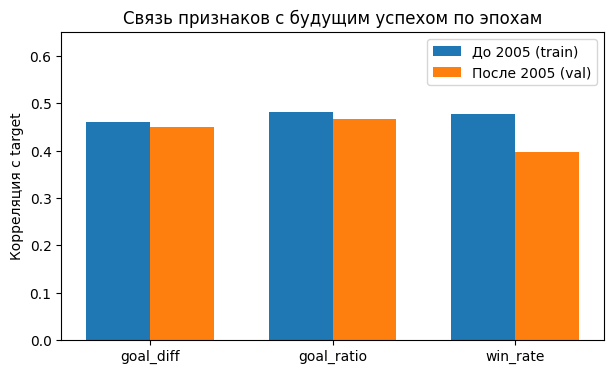

In [18]:
# сравнение корреляций признаков с target
x = np.arange(len(features))
width = 0.35

plt.figure(figsize=(7, 4))
plt.bar(x - width/2, corr_train, width, label='До 2005 (train)')
plt.bar(x + width/2, corr_val, width, label='После 2005 (val)')
plt.xticks(x, features)
plt.ylabel('Корреляция с target')
plt.ylim(0, 0.65)
plt.title('Связь признаков с будущим успехом по эпохам')
plt.legend()
plt.show()


In [19]:
# проверка масштаба признаков для укороченного сезона 1994 года
l94 = eda_pairs[eda_pairs['year'] == 1994]
oth = eda_pairs[eda_pairs['year'] != 1994]
scale_check = pd.DataFrame({
    'Показатель': [
        'Средний |goal_diff|',
        'Стандартное отклонение goal_diff',
        'Стандартное отклонение goal_ratio'
    ],
    '1994 год (48 матчей)': [
        round(l94['goal_diff'].abs().mean(), 1),
        round(l94['goal_diff'].std(), 1),
        round(l94['goal_ratio'].std(), 3)
    ],
    'Остальные годы (~82 матча)': [
        round(oth['goal_diff'].abs().mean(), 1),
        round(oth['goal_diff'].std(), 1),
        round(oth['goal_ratio'].std(), 3)
    ]
})
print("\nМасштаб признаков: укороченный сезон 1994 против стандартных сезонов:")
scale_check



Масштаб признаков: укороченный сезон 1994 против стандартных сезонов:


,Показатель,1994 год (48 матчей),Остальные годы (~82 матча)
0,Средний |goal_diff|,25.400,37.500
1,Стандартное отклонение goal_diff,30.400,48.700
2,Стандартное отклонение goal_ratio,0.215,0.194


In [20]:
# Вопрос 2
# Определяем, была ли команда успешной в текущем сезоне (выше медианы своего года)

eda_pairs['current_success'] = (eda_pairs['win_rate'] > eda_pairs['year'].map(medians)).astype(int)

# Матрица переходов (train + val, без test)
trans_matrix = pd.crosstab(eda_pairs['current_success'], eda_pairs['target'], normalize='index')
print("Матрица переходов (текущий успех -> будущий target):")
trans_matrix.round(3)


Матрица переходов (текущий успех -> будущий target):


target,0,1
current_success,,
0,0.715,0.285
1,0.296,0.704


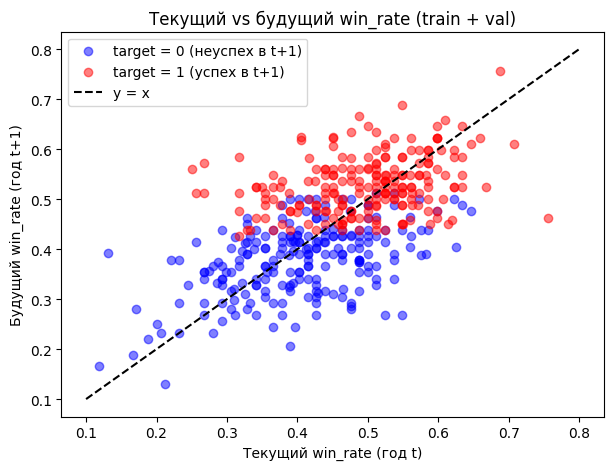

In [21]:
# scatter plot текущего винрейта против будущего винрейта
plt.figure(figsize=(7, 5))

# Точки для команд, оставшихся неуспешными в следующем году
plt.scatter(
    eda_pairs[eda_pairs['target'] == 0]['win_rate'],
    eda_pairs[eda_pairs['target'] == 0]['win_rate_next'],
    alpha=0.5,
    color='blue',
    label='target = 0 (неуспех в t+1)'
)

# Точки для команд, ставших успешными в следующем году
plt.scatter(
    eda_pairs[eda_pairs['target'] == 1]['win_rate'],
    eda_pairs[eda_pairs['target'] == 1]['win_rate_next'],
    alpha=0.5,
    color='red',
    label='target = 1 (успех в t+1)'
)

# Опорная прямая y = x
plt.plot([0.1, 0.8], [0.1, 0.8], 'k--', label='y = x')
plt.xlabel('Текущий win_rate (год t)')
plt.ylabel('Будущий win_rate (год t+1)')
plt.title('Текущий vs будущий win_rate (train + val)')
plt.legend()
plt.show()


In [22]:
# Самая сильная разница в винрейте в парах (train + val)
eda_pairs['diff_rate'] = eda_pairs['win_rate_next'] - eda_pairs['win_rate']

print("Самое сильное падение винрейта:")
drop = eda_pairs.sort_values('diff_rate').iloc[0]
print(drop[['team', 'year', 'target_year', 'win_rate', 'win_rate_next', 'goal_diff', 'target']])

print("\nСамый сильный взлет винрейта:")
rise = eda_pairs.sort_values('diff_rate', ascending=False).iloc[0]
print(rise[['team', 'year', 'target_year', 'win_rate', 'win_rate_next', 'goal_diff', 'target']])


Самое сильное падение винрейта:
team             Detroit Red Wings
year                          1995
target_year                   1996
win_rate                     0.756
win_rate_next                0.463
goal_diff                      144
target                           1
Name: 124, dtype: object

Самый сильный взлет винрейта:
team             Quebec Nordiques
year                         1991
target_year                  1992
win_rate                     0.25
win_rate_next                0.56
goal_diff                     -63
target                          1
Name: 36, dtype: object


**Ответ 3.2:**

Исходя из проведенного анализа, мы видим, что после 2005 года (по 2008 год, на валидационной выборке) после отмены ничьих винрейт стал меньше коррелировать с успехом команды в следующем году (упал с 0.477 до 0.396), а разность забитых и пропущенных голов и их отношение изменились не так сильно (с 0.461 и 0.481 до 0.45 и 0.467 соответственно) и после 2005 года коррелируют с успехом сильнее винрейта.

Также на примере 1994 года мы видим, что в нём модуль `goal_diff` был значительно меньше, чем в остальные годы с большим количеством матчей (25.4 против 37.5), а стандартное отклонение с 48.7 в остальные годы упало до 30.4. А введённый нами относительный признак `goal_ratio` (`goals_for` / `goals_against`) остался сопоставимым с остальными годами (0.215 в 1994 году против 0.194 в среднем по годам).

Однако признаки на основе голов не учитывают, что, например, команды с агрессивным стилем могут забить много голов командам со слабой защитой, тогда как командам с сильной обороной и аккуратной игрой они могут проиграть не с таким разрывом, потому что такие команды будут играть от обороны и действовать от ошибок противника, забивая меньше голов, но пропуская еще меньше.

Приведу пример: команда A может сыграть с командой B со счетом 10:1, а с командами C и D со счетами 1:2. В таком случае у команды A будет `goal_ratio` = (10 + 1 + 1) / (1 + 2 + 2) = 2.4, хотя винрейт будет всего 0.33, и она не может считаться успешной.

Поэтому нельзя отбрасывать `win_rate`. Корреляция 0.396 всё еще значительная, и данный признак позволяет оценить команду с другой стороны, нежели её голы. Поэтому целесообразно использовать признаки на основе голов в связке с винрейтом.

<br>
Матрица переходов показывает, что target текущего года имеет явную зависимость от target предыдущего года. Успешная команда остается успешной с вероятностью 70.4%, а неуспешная остается неуспешной с вероятностью 71.5%.

На втором графике мы видим, что, как правило, успешная в текущем году команда будет успешной и в следующем году. Однако если посмотреть на винрейт > 0.6, то мы видим, что в будущем году он становится ниже. А на низком винрейте наоборот большинство команд увеличивают процент побед в следующем году. То есть регрессия к среднему все равно присутствует. Ярким примером изменений винрейта в соседних годах являются команды Detroit Red Wings в 1995-1996 годах (падение с 0.756 до 0.463, но она все равно осталась успешной) и Quebec Nordiques в 1991-1992 годах (рост с 0.25 до 0.56).

Но данный анализ не учитывает все возможные факторы роста и падения винрейта команд. Возможно, ключевые игроки покинули состав, либо были травмированы и не могли играть долгое время. Также в данном датасете не отражена информация по голам за каждый матч, из которой можно было бы определить медианное количество забитых и пропущенных голов за матч для каждой команды, чтобы сгладить разницу между богатыми и бедными на голы матчами.



## Раздел 4. Модели и эксперименты: 25 баллов

### 4.1. Постройте ориентиры

На train обучите простой константный baseline и оцените его на validation.
Отдельно используйте текущий `win_rate` как простую оценку для ранжирования
будущего класса. Посчитайте ROC-AUC обоих ориентиров и объясните,
какую планку задаёт каждый из них для обучаемой модели.

In [23]:
# 4.1. Ваш код
# Добавьте ячейки при необходимости.

# Константный baseline (обучаем DummyClassifier на train и оцениваем на validation)
dummy = DummyClassifier(strategy='prior')
dummy.fit(train[['win_rate']], train['target'])
dummy_auc = roc_auc_score(val['target'], dummy.predict_proba(val[['win_rate']])[:, 1])

# Эвристический ориентир (ранжирование по текущему win_rate)
win_rate_auc = roc_auc_score(val['target'], val['win_rate'])

# Вывод результатов
print(f"ROC-AUC константного baseline (Dummy):        {dummy_auc:.4f}")
print(f"ROC-AUC эвристики (ранжирование по win_rate): {win_rate_auc:.4f}")


ROC-AUC константного baseline (Dummy):        0.5000
ROC-AUC эвристики (ранжирование по win_rate): 0.7568


**Ответ 4.1:**

Константный бейзлайн выдает всем объектам одинаковую вероятность, равную доле класса 1 на обучающей выборке. Такая модель всегда выдает 0.5 ROC-AUC, потому что не способна отранжировать данные. Любая полезная модель должна быть выше этой отметки.

Эвристический бейзлайн с ранжированием по `win_rate` дает нам 0.7568 ROC-AUC. Оценка происходит путем сравнения значения win_rate между всеми парами, где у одного target=1, а у другого target=0. Если win_rate у target=1 выше, тогда такая пара считается в количество верных ответов, а если win_rate у target=1 ниже, чем у target=0, то такая пара будет неверной. И в итоге метрика считается как частное количества верных ответов и общего количества пар.

Наша модель должна иметь ROC-AUC выше 0.7568, чтобы она имела смысл.



### 4.2. Постройте первую модель

Обучите логистическую регрессию. Самостоятельно выберите признаки и обоснуйте выбор.
Обработку пропусков и масштабирование включите в Pipeline и обучайте только на train.
Посчитайте ROC-AUC на validation и сравните с обоими ориентирами.
Объясните результат без использования test.

In [24]:
# 4.2. Ваш код
# Добавьте ячейки при необходимости.

# Обновляем срезы train и val из pairs (с добавленным признаком goal_ratio)
train = pairs[pairs['target_year'] <= 2005]
val = pairs[(pairs['target_year'] >= 2006) & (pairs['target_year'] <= 2008)]

# Берем три ключевых признака, исследованных в EDA
features = ['win_rate', 'goal_diff', 'goal_ratio']

# Создаем Pipeline: обработка пропусков -> масштабирование -> логистическая регрессия
model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=42))
])

# Обучаем Pipeline строго на train
model.fit(train[features], train['target'])


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('clf', LogisticRegression(random_state=42))])

In [25]:
# Получаем вероятности класса 1 на validation и считаем ROC-AUC
val_probs = model.predict_proba(val[features])[:, 1]
val_auc = roc_auc_score(val['target'], val_probs)

print(f"ROC-AUC логистической регрессии (3 признака): {val_auc:.4f}\n")

# Анализ весов признаков
print("Веса признаков в модели:")
for f, coef in zip(features, model.named_steps['clf'].coef_[0]):
    print(f"  {f:12s}: {coef:.3f}")


ROC-AUC логистической регрессии (3 признака): 0.7746

Веса признаков в модели:
  win_rate    : 0.585
  goal_diff   : -0.039
  goal_ratio  : 0.730


**Ответ 4.2:**

В данной модели мы взяли 3 признака: `win_rate`, `goal_diff`, `goal_ratio`, которые были отобраны в предыдущих пунктах.

Логистическая регрессия превзошла эвристику с ранжированием по винрейту (константный бейзлайн, естественно, тоже), получив ROC-AUC 0.7746. В эвристическом бейзлайне был использован только `win_rate`, а тут мы дополнительно использовали информацию о голах, и признак `goal_ratio` даже получил самый большой вес, что означает его наибольшую информативность, но и `win_rate` тоже имеет положительный вес и оказался полезным. Также мы видим отрицательный вес у признака `goal_diff`, что говорит о его избыточности, ведь он несет ту же информацию, что и `goal_ratio`, только из-за своего абсолютного выражения оказывается хуже.

### 4.3. Проведите собственный эксперимент

Выберите одно осмысленное изменение: состав признаков, способ обработки данных,
параметры или другой алгоритм. До запуска запишите ожидаемый эффект и его причину.
Изменяйте одну понятную часть решения, сравните варианты на validation
и зафиксируйте выбор финальной модели до просмотра test.
Дополнительные эксперименты допустимы, но их количество само по себе не оценивается.

В данном эксперименте уберем признак `goal_diff`, так как он несет такую же информацию как и `goal_ratio`, но из-за малого числа игр в 1994 году вносит ненужный шум, приводящий к отрицательному весу. Ожидаем, что исключение этого признака окажет положительное влияние на метрики или как минимум упростит модель без потери качества.

In [26]:
# 4.3. Ваш код
# Добавьте ячейки при необходимости.

features_exp = ['win_rate', 'goal_ratio']
# Создаем аналогичный Pipeline и обучаем строго на train
model_exp = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=42))
])
model_exp.fit(train[features_exp], train['target'])

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('clf', LogisticRegression(random_state=42))])

In [27]:
# Оцениваем вероятность класса 1 на validation
val_probs_exp = model_exp.predict_proba(val[features_exp])[:, 1]
val_auc_exp = roc_auc_score(val['target'], val_probs_exp)

print(f"ROC-AUC экспериментальной модели (2 признака):    {val_auc_exp:.4f}")

# Веса признаков в экспериментальной модели
print("Веса признаков в финальной модели:")
for f, coef in zip(features_exp, model_exp.named_steps['clf'].coef_[0]):
    print(f"  {f:12s}: {coef:.3f}")

ROC-AUC экспериментальной модели (2 признака):    0.7756
Веса признаков в финальной модели:
  win_rate    : 0.577
  goal_ratio  : 0.700


**Ответ 4.3:**

Исходя из результатов предыдущего пункта, здесь мы убрали признак `goal_diff`, чтобы он не создавал шумов, ведь все данные из него мы получаем в более полезном `goal_ratio`.

Это позволило нам ещё немного поднять ROC-AUC: с 0.7746 из предыдущей модели до 0.7756.

Сейчас оба признака имеют положительные веса и вносят существенный вклад, не мешая друг другу, так как содержат разную информацию.

В качестве финальной модели фиксируем логистическую регрессию на признаках `goal_ratio` и `win_rate`, протестированную в этом пункте.

## Раздел 5. Итоговая оценка и анализ ошибок: 15 баллов

### 5.1. Проведите итоговую оценку

Зафиксируйте выбранную модель, признаки и параметры, затем один раз оцените её на test.
Покажите ROC-AUC, F1 и accuracy при пороге 0.5 для выбранной модели
и сопоставимых baseline. Объясните различия между метриками и сравните
результаты validation и test. После этого не меняйте выбранное решение.

In [28]:
# 5.1. Ваш код
# Добавьте ячейки при необходимости.

# Включаем в тестовую выборку столбец goal_ratio)
test = pairs[(pairs['target_year'] >= 2009) & (pairs['target_year'] <= 2011)]

# Фиксация признаков и модели, выбранной в эксперименте
features = ['win_rate', 'goal_ratio']
final_model = model_exp

# Прогнозы финальной модели на test
test_probs_model = final_model.predict_proba(test[features])[:, 1]
test_preds_model = (test_probs_model >= 0.5).astype(int)

# Прогнозы Dummy baseline на test
test_probs_dummy = dummy.predict_proba(test[features])[:, 1]
test_preds_dummy = (test_probs_dummy >= 0.5).astype(int)

# Прогнозы эвристики по win_rate на test (порог 0.5)
test_probs_win = test['win_rate']
test_preds_win = (test_probs_win >= 0.5).astype(int)


In [29]:
# Итоговая сводная таблица на test
test_summary = pd.DataFrame({
    'Модель / Ориентир': [
        'Константный baseline (Dummy)',
        'Эвристика по win_rate',
        'Финальная модель (LogReg)'
    ],
    'ROC-AUC': [
        round(roc_auc_score(test['target'], test_probs_dummy), 4),
        round(roc_auc_score(test['target'], test_probs_win), 4),
        round(roc_auc_score(test['target'], test_probs_model), 4)
    ],
    'Accuracy (порог 0.5)': [
        round(accuracy_score(test['target'], test_preds_dummy), 4),
        round(accuracy_score(test['target'], test_preds_win), 4),
        round(accuracy_score(test['target'], test_preds_model), 4)
    ],
    'F1-score (порог 0.5)': [
        round(f1_score(test['target'], test_preds_dummy), 4),
        round(f1_score(test['target'], test_preds_win), 4),
        round(f1_score(test['target'], test_preds_model), 4)
    ]
})
print("Результаты на ТЕСТОВОЙ выборке (2009–2011 гг.):")
display(test_summary)

# Сравнение результатов финальной модели: validation vs test
print("\nСравнение финальной модели: Validation vs Test:")
val_preds_model = (val_probs_exp >= 0.5).astype(int)
print(f"Validation (2006-2008): ROC-AUC = {val_auc_exp:.4f}, Accuracy = {accuracy_score(val['target'], val_preds_model):.4f}, F1 = {f1_score(val['target'], val_preds_model):.4f}")
print(f"Test       (2009-2011): ROC-AUC = {roc_auc_score(test['target'], test_probs_model):.4f}, Accuracy = {accuracy_score(test['target'], test_preds_model):.4f}, F1 = {f1_score(test['target'], test_preds_model):.4f}")


Результаты на ТЕСТОВОЙ выборке (2009–2011 гг.):


,Модель / Ориентир,ROC-AUC,Accuracy (порог 0.5),F1-score (порог 0.5)
0,Константный baseline (Dummy),0.5000,0.5281,0.0000
1,Эвристика по win_rate,0.7404,0.6404,0.6522
2,Финальная модель (LogReg),0.7568,0.6404,0.6800



Сравнение финальной модели: Validation vs Test:
Validation (2006-2008): ROC-AUC = 0.7756, Accuracy = 0.7191, F1 = 0.7573
Test       (2009-2011): ROC-AUC = 0.7568, Accuracy = 0.6404, F1 = 0.6800


**Ответ 5.1:**

Наша модель оказалась лучше обоих бейзлайнов. На тестовой выборке ROC-AUC составил 0.7568, и при пороге 0.5 мы получили Accuracy 0.6404 и F1-score 0.68.

ROC-AUC отражает качество ранжирования. В нашем случае эта метрика показывает, что почти в 76% случаев модель верно определяет, какая из двух случайных команд сильнее.

Accuracy показывает долю верных ответов. Она сильно зависит от порога. Возможно, модель показала бы лучший результат по этой метрике, если изменить порог вероятности, с которой можно считать команду успешной.

F1-score оценивает только класс успешных команд. Константный бейзлайн выставил всем нули, поэтому F1-score получился 0. Также обычно он полезен, если в датасете классы не сбалансированы по количеству, потому что он показывает качество определения одного менее распространенного класса.

На тестовой выборке метрики немного просели по сравнению с валидационной. Это можно объяснить тем, что модель обучалась на старых данных, а со временем конкуренция росла и результат становился более непредсказуемым.

### 5.2. Разберите ошибки

Выберите от трёх до пяти ошибок финальной модели по явно указанному принципу.
Это могут быть наиболее уверенные ошибки, отдельный тип ошибки или другой
обоснованный набор. Покажите идентификаторы строк, вероятности и значения,
необходимые для анализа. Найдите общие черты и различия; отделите факты
из таблицы от гипотез и назовите данные, нужные для проверки одной гипотезы.

In [30]:
# 5.2. Ваш код
# Добавьте ячейки при необходимости.

# Добавляем вероятности и типы ошибок в копию тестовой выборки
test_errors = test.copy()
test_errors['prob'] = test_probs_model
test_errors['pred'] = test_preds_model

# Определяем тип ошибки при пороге 0.5
test_errors['error_type'] = 'Correct'
test_errors.loc[(test_errors['pred'] == 1) & (test_errors['target'] == 0), 'error_type'] = 'False Positive'
test_errors.loc[(test_errors['pred'] == 0) & (test_errors['target'] == 1), 'error_type'] = 'False Negative'

# Отбираем топ-2 самые уверенные False Positive и топ-2 самые уверенные False Negative
errors_only = test_errors[test_errors['pred'] != test_errors['target']]
top_fp = errors_only[errors_only['error_type'] == 'False Positive'].sort_values('prob', ascending=False).head(2)
top_fn = errors_only[errors_only['error_type'] == 'False Negative'].sort_values('prob', ascending=True).head(2)

selected_errors = pd.concat([top_fp, top_fn])

# Выводим таблицу с нужными для анализа признаками
cols = ['team', 'year', 'target_year', 'win_rate', 'goal_ratio', 'prob', 'pred', 'target', 'win_rate_next', 'error_type']
summary_errors = selected_errors[cols].copy()
summary_errors['goal_ratio'] = summary_errors['goal_ratio'].round(3)
summary_errors['prob'] = summary_errors['prob'].round(3)

print("Топ-4 наиболее уверенных ошибок модели:")
display(summary_errors)


Топ-4 наиболее уверенных ошибок модели:


,team,year,target_year,win_rate,goal_ratio,prob,pred,target,win_rate_next,error_type
429,Boston Bruins,2008,2009,0.646,1.398,0.920,1,0,0.476,False Positive
474,New Jersey Devils,2009,2010,0.585,1.162,0.782,1,0,0.463,False Positive
435,Colorado Avalanche,2008,2009,0.390,0.774,0.238,0,1,0.524,False Negative
483,Tampa Bay Lightning,2009,2010,0.415,0.835,0.307,0,1,0.561,False Negative


**Ответ 5.2:**

Здесь мы вывели по 2 ошибочных примера, когда модель давала большую уверенность в успехе и, наоборот, когда она давала низкую вероятность успеха.

Во всех этих случаях винрейт в предсказываемом году значительно изменился - на 0.12-0.17. Модель опирается только на статистику прошлого года, поэтому не могла предсказать такие изменения. Первые два случая отличаются от последних двух тем, что в первых модель ошибочно посчитала команды успешными в новом году, а в последних - ошибочно посчитала неуспешными. То есть модель может как переоценивать, так и недооценивать команды.

По таблице мы видим, что у команды Boston Bruins в 2008 году был винрейт 0.646, а соотношение забитых голов к пропущенным - 1.398. Эти статистические данные превосходят большинство других команд, поэтому модель была на 92% уверена в успехе этой команды.

Предположу, что падение винрейта на 0.17 могло быть вызвано не только случайностью. Возможно, была смена состава или могло ухудшиться здоровье ключевых игроков. Чтобы проверить эту гипотезу, нужны данные по составу команды, трансферам, количеству пропущенных матчей самыми результативными игроками команды.

## Раздел 6. Выводы и воспроизводимость: 5 баллов

### 6.1. Сформулируйте выводы

Сформулируйте основные выводы и ограничения работы со ссылками на свои графики,
строки и метрики. Опишите минимум два решения, которые вы изменили
или подтвердили после получения результатов. Назовите одно улучшение,
которое вы сознательно не стали выполнять, и объясните причину.
Убедитесь, что последовательность работы и финальные параметры можно воспроизвести.

**Ответ 6.1:**

В результате работы мы получили модель логистической регрессии, которая была обучена на признаках `win_rate` и `goal_ratio`. На тестовой выборке она показала ROC-AUC = 0.7568, Accuracy = 0.6404, F1-score = 0.68, превзойдя оба бейзлайна.

Анализ в пункте 3.2 показал, что самым устойчивым признаком даже после исчезновения ничьих оказался `goal_ratio`, показывающий отношение забитых шайб к пропущенным, а корреляция винрейта и успеха снизилась после отмены ничьих (п. 3.2, график 1).

Примерно 70% команд сохраняют свой статус текущего года в следующем году. Также присутствует регрессия к среднему: у лидеров винрейт снижается, а у аутсайдеров повышается (п. 3.2, график 2).

Ограничения работы заключаются в нехватке данных датасета для построения более точной модели. Например, как было упомянуто в пункте 3.2, в датасете нет статистики по каждому матчу, поэтому нельзя посчитать медиану числа голов по каждой команде. Также в пункте 5.2 дополнено, что в датасете отсутствует информация о составе игроков на каждый матч, трансферах, травмах, заменах, что не позволяет повысить качество предсказаний модели.

После получения результатов мы подтвердили целесообразность введения признака `goal_ratio`, а также отказались от использования в финальной модели признака `goal_diff` из-за его меньшей гибкости по сравнению с `goal_ratio` и отсутствия полезной информации при наличии `goal_ratio` (пункты 4.2 - 4.3).


Одно из "улучшений", которое можно было бы применить, но оно не рационально в наших условиях - это использование более сложной модели (например, случайный лес), потому что у нас слишком мало данных, а именно 338 строк на обучающей выборке, что вызовет переобучение и метрики на тесте упадут.

Работа полностью воспроизводима, для обучения моделей был установлен random_state=42.